#Question 1

Part (b)

In [1]:
import numpy as np

K = 8
B = K + 1


triples = np.array([
    (n_slow, n_steady, n_fast)
    for n_slow in range(K + 1)
    for n_steady in range(K + 1 - n_slow)
    for n_fast in range(K + 1 - n_slow - n_steady)
    if n_slow + n_steady + n_fast >= 1
])

messages = np.array([1, B, B**2])
sums = triples @ messages


decoded = np.column_stack((
    sums % B,
    (sums // B) % B,
    sums // B**2
))


assert len(np.unique(sums)) == len(triples)
assert np.array_equal(decoded, triples)

print("Count triples checked:", len(triples))
print("All sums are unique and all counts decode correctly.")

Count triples checked: 164
All sums are unique and all counts decode correctly.


#Question 2

## Part (a)(ii)

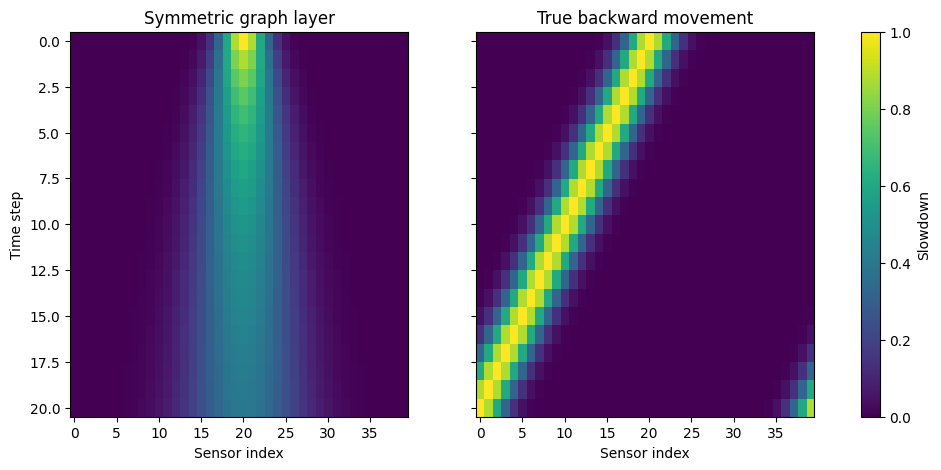

In [2]:
import numpy as np
import matplotlib.pyplot as plt

sensors = np.arange(40)
a = 0.0
b = 0.5

initial = np.exp(-((sensors - 20) ** 2) / 8)

predicted = [initial.copy()]
actual = [initial.copy()]

for step in range(20):
    current_prediction = predicted[-1]

    next_prediction = (
        a * current_prediction
        + b * (
            np.roll(current_prediction, 1)
            + np.roll(current_prediction, -1)
        )
    )

    predicted.append(next_prediction)

    next_actual = np.roll(actual[-1], -1)
    actual.append(next_actual)

predicted = np.array(predicted)
actual = np.array(actual)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

im = axes[0].imshow(
    predicted,
    aspect="auto",
    origin="upper",
    cmap="viridis",
    vmin=0,
    vmax=1
)
axes[0].set_title("Symmetric graph layer")
axes[0].set_xlabel("Sensor index")
axes[0].set_ylabel("Time step")

axes[1].imshow(
    actual,
    aspect="auto",
    origin="upper",
    cmap="viridis",
    vmin=0,
    vmax=1
)
axes[1].set_title("True backward movement")
axes[1].set_xlabel("Sensor index")

fig.colorbar(im, ax=axes, label="Slowdown")
plt.show()